# YOLOv8 vs YOLO11 vs YOLO26: Comparison

Reads the `results_{model}.json`, `results.csv`, and saved plots that each training notebook
(`train_yolov8.ipynb` / `train_yolo11.ipynb` / `train_yolo26.ipynb`) wrote into its own
`{model}_outputs/` folder next to this notebook. Purely local, no Drive mount, no GPU, no
re-running inference. If an output folder is missing, that model is skipped from the
comparison rather than erroring out or being faked.

In [1]:
import json
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

BASE = Path('.')
MODELS = ['yolov8', 'yolo11', 'yolo26']

results = {}
for m in MODELS:
    p = BASE / f'{m}_outputs' / f'results_{m}.json'
    if p.exists():
        with open(p) as f:
            results[m] = json.load(f)
        print(f"loaded {m}: {p}")
    else:
        print(f"SKIPPING {m}: {p} not found")

if not results:
    raise RuntimeError("No results_*.json found. Run at least one training notebook and drop "
                        "its {model}_outputs folder next to this notebook first.")

loaded yolov8: yolov8_outputs\results_yolov8.json
loaded yolo11: yolo11_outputs\results_yolo11.json
loaded yolo26: yolo26_outputs\results_yolo26.json


## Comparison table

In [2]:
rows = []
for m, r in results.items():
    met = r['metrics']
    row = {
        'model': m, 'scale': r.get('model_scale'),
        'mAP50': met['map50'], 'mAP50-95': met['map50_95'],
        'precision': met['precision'], 'recall': met['recall'],
    }
    for cls_name, ap in met.get('per_class_ap50', {}).items():
        row[f'AP50[{cls_name}]'] = ap
    rows.append(row)

comparison_df = pd.DataFrame(rows).set_index('model')
comparison_df

,scale,mAP50,mAP50-95,precision,recall,AP50[Glioma],AP50[Meningioma],AP50[No Tumor],AP50[Pituitary]
model,,,,,,,,,
yolov8,yolov8s.pt,0.962098,0.779722,0.964265,0.928640,0.937308,0.994151,0.985000,0.931934
yolo11,yolo11s.pt,0.966437,0.779725,0.961776,0.945083,0.935883,0.994366,0.994800,0.940698
yolo26,yolo26s.pt,0.963867,0.779476,0.966671,0.920461,0.924660,0.994366,0.994899,0.941545


## Bar charts

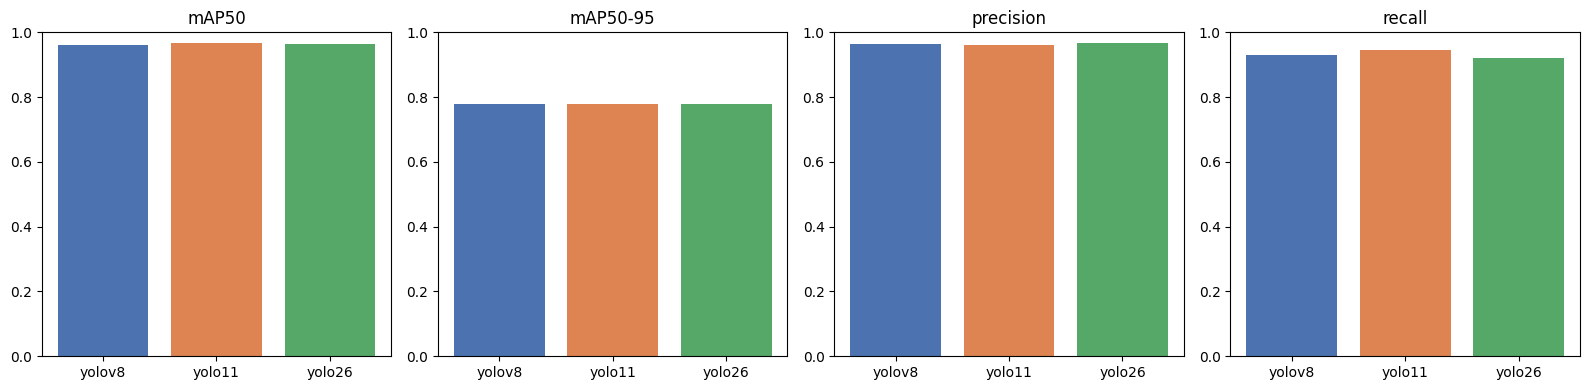

In [3]:
metrics_to_plot = ['mAP50', 'mAP50-95', 'precision', 'recall']
fig, axes = plt.subplots(1, len(metrics_to_plot), figsize=(4 * len(metrics_to_plot), 4))
colors = {'yolov8': '#4C72B0', 'yolo11': '#DD8452', 'yolo26': '#55A868'}

for ax, metric in zip(axes, metrics_to_plot):
    vals = comparison_df[metric]
    ax.bar(vals.index, vals.values, color=[colors[m] for m in vals.index])
    ax.set_title(metric)
    ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

## Training curves: loss and mAP50 across epochs, overlaid

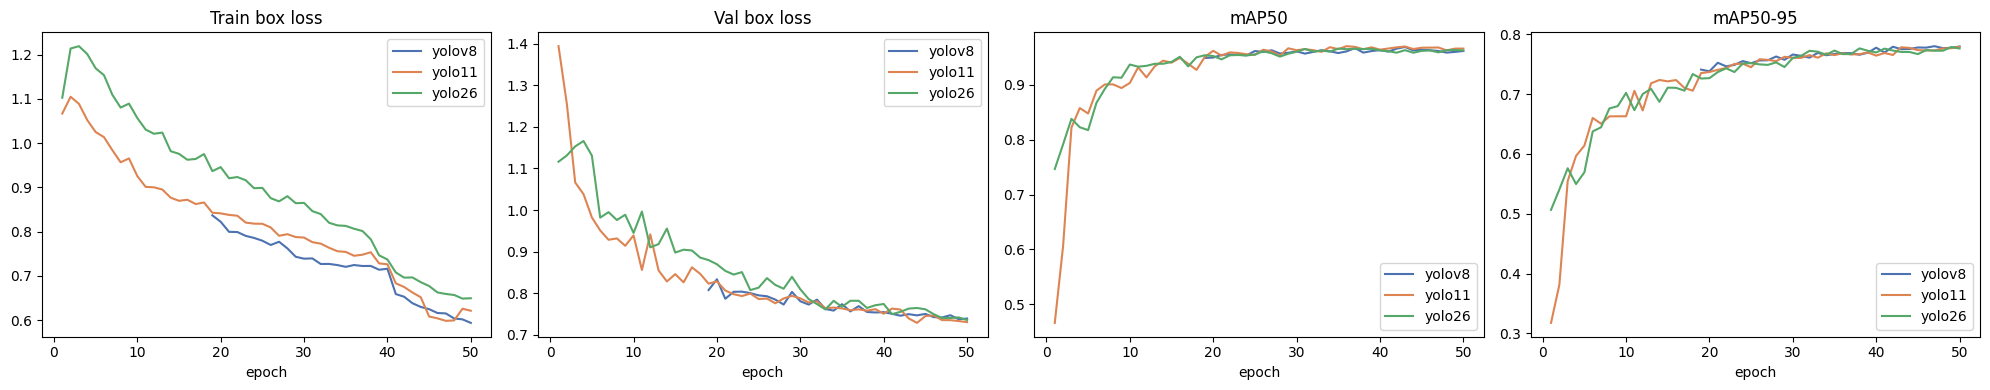

In [4]:
curve_cols = [
    ('train/box_loss', 'Train box loss'),
    ('val/box_loss', 'Val box loss'),
    ('metrics/mAP50(B)', 'mAP50'),
    ('metrics/mAP50-95(B)', 'mAP50-95'),
]
fig, axes = plt.subplots(1, len(curve_cols), figsize=(5 * len(curve_cols), 4))

for m in results:
    csv_path = BASE / f'{m}_outputs' / 'runs' / 'results.csv'
    if not csv_path.exists():
        print(f"no results.csv for {m}, skipping its curves")
        continue
    df = pd.read_csv(csv_path)
    df.columns = [c.strip() for c in df.columns]
    for ax, (col, title) in zip(axes, curve_cols):
        if col in df.columns:
            ax.plot(df['epoch'], df[col], label=m, color=colors.get(m))
            ax.set_title(title)
            ax.set_xlabel('epoch')
            ax.legend()

plt.tight_layout()
plt.show()

## Confusion matrices, side by side

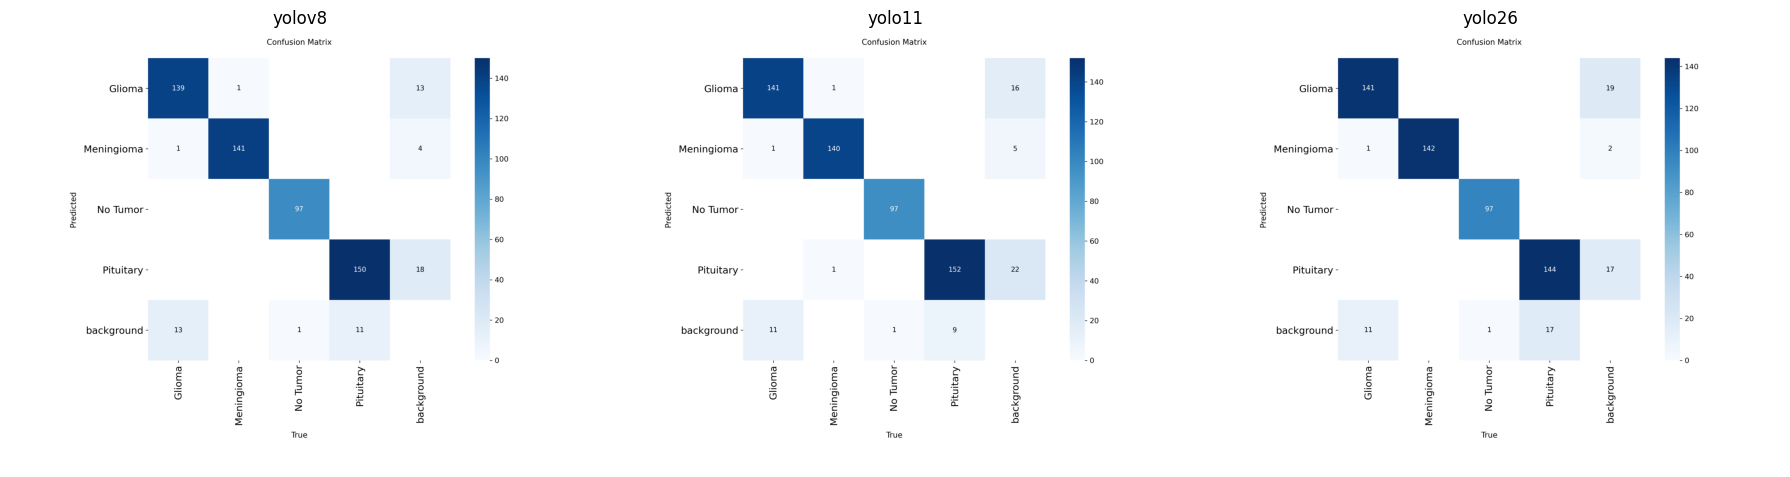

In [5]:
fig, axes = plt.subplots(1, len(results), figsize=(6 * len(results), 6))
axes = [axes] if len(results) == 1 else axes

for ax, m in zip(axes, results):
    cm_path = BASE / f'{m}_outputs' / 'runs' / 'confusion_matrix.png'
    if cm_path.exists():
        ax.imshow(Image.open(cm_path))
    else:
        ax.text(0.5, 0.5, 'not found', ha='center', va='center')
    ax.set_title(m)
    ax.axis('off')
plt.tight_layout()
plt.show()

## Qualitative: validation-batch predictions vs. ground truth

In [ ]:
fig, axes = plt.subplots(len(results), 2, figsize=(14, 7 * len(results)))
axes = axes.reshape(len(results), 2)

for row, m in zip(axes, results):
    gt_path = BASE / f'{m}_outputs' / 'runs' / 'val_batch0_labels.jpg'
    pred_path = BASE / f'{m}_outputs' / 'runs' / 'val_batch0_pred.jpg'
    for ax, path, label in zip(row, [gt_path, pred_path], ['Ground truth', 'Predicted']):
        if path.exists():
            ax.imshow(Image.open(path))
        else:
            ax.text(0.5, 0.5, 'not found', ha='center', va='center')
        ax.set_title(f'{m}: {label}')
        ax.axis('off')
plt.tight_layout()
plt.show()

## Summary and caveats

- Comparison is under a **matched training budget** (same epochs/imgsz/seed) where the training
  notebooks record it, not necessarily each model's best achievable performance.
- Any `notes` field from a model's results JSON (e.g. the YOLO26 architecture-difference caveat)
  is surfaced below.
- **This is not a validated clinical tool.** For architecture comparison only.

In [7]:
missing = [m for m in MODELS if m not in results]
if missing:
    print(f"Missing results (excluded from the comparison above): {missing}")

for m, r in results.items():
    if r.get('notes'):
        print(f"[{m}] {r['notes']}")

[yolo26] YOLO26 removes NMS/DFL and uses a different default training recipe (MuSGD, ProgLoss/STAL) than YOLOv8/YOLO11, so matching epochs/imgsz/seed alone does not make this a fully controlled comparison.
